# Controlled modeling improvement study

This study preserves the historical prediction result. It uses only January–October development data and performs **no November–December prediction or evaluation**. Run `python -m experiments.modeling_study` once before this notebook. This notebook reads saved study tables and probabilities and does not fit models.

See `reports/modeling_improvement_study.md` for the full audit, predeclared configurations, negative results, limits and recommendations.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_curve, precision_recall_curve
ROOT=Path.cwd()
if not (ROOT/'experiments/modeling_study.py').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from experiments.modeling_study import protected_hashes
OUT=ROOT/'outputs/experiments/modeling_study'
assert (OUT/'preservation_check.json').exists(), 'Run the study first.'
assert protected_hashes()==json.loads((OUT/'preservation_check.json').read_text())['files']
FIGURES=OUT/'figures'; FIGURES.mkdir(exist_ok=True)
internal=pd.read_csv(OUT/'internal_folds.csv')
summary=pd.read_csv(OUT/'internal_summary.csv')
validation=pd.read_csv(OUT/'validation_metrics.csv')
monthly=pd.read_csv(OUT/'validation_monthly.csv')
print('Verified: original artifacts unchanged.')
print('Frozen shortlist:',json.loads((OUT/'shortlist.json').read_text()))
plt.rcParams.update({'figure.figsize':(12,5),'axes.spines.top':False,'axes.spines.right':False})
def save(name):
    plt.tight_layout(); plt.savefig(FIGURES/f'{name}.png',dpi=160,bbox_inches='tight'); plt.show(); plt.close()

Matplotlib is building the font cache; this may take a moment.


Verified: original artifacts unchanged.
Frozen shortlist: {'candidates': ['decision_tree_original', 'forest_interactions_d14', 'logistic_regression_original', 'lr_cyclic_C1', 'lr_interactions_C1', 'lr_keyed_C1', 'random_forest_original'], 'internal_champion': 'forest_interactions_d14'}


## 1. Audit and chronological design

Original month/day-of-year and weekdays are linear numerical effects, scheduled clocks have a midnight discontinuity, and flight numbers can repeat across carriers. The study compares carrier-qualified flight IDs, cyclic calendar/clock features and categorical weekdays, then a few carrier/origin/time-band interactions. Raw clock ramps remain available. No observed delays, target aggregates or metadata enter the feature transform.

Three expanding folds separate **fit / threshold choice / assessment**: Jan–Mar / April / May; Jan–Apr / May / June; Jan–May / June / July–August. Candidate selection uses mean later-period F1, with mean ROC-AUC as tie-break. The 14 configurations were set before validation scoring. Shared histories and only three periods limit certainty.

,month,n,positive_count,prevalence
0,1,26483,5091,0.192237
1,2,23690,4961,0.209413
2,3,27973,6416,0.229364
3,4,27662,6405,0.231545
4,5,28233,6645,0.235363
5,6,27234,8016,0.294338
6,7,28485,8639,0.303282
7,8,28841,6592,0.228564
8,9,27122,3908,0.144090
9,10,28653,4426,0.154469


,name,family,encoding,parameters
0,logistic_regression_original,logistic_regression,original,"{'C': 1.0, 'class_weight': None, 'dual': False..."
1,decision_tree_original,decision_tree,original,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit..."
2,random_forest_original,random_forest,original,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
3,lr_cyclic_C1,logistic_regression,cyclic,"{'C': 1, 'class_weight': None, 'dual': False, ..."
4,lr_keyed_C1,logistic_regression,keyed,"{'C': 1, 'class_weight': None, 'dual': False, ..."
5,lr_interactions_C1,logistic_regression,interactions,"{'C': 1, 'class_weight': None, 'dual': False, ..."
6,lr_interactions_C0.1,logistic_regression,interactions,"{'C': 0.1, 'class_weight': None, 'dual': False..."
7,lr_interactions_C10,logistic_regression,interactions,"{'C': 10, 'class_weight': None, 'dual': False,..."
8,tree_interactions_d6,decision_tree,interactions,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit..."
9,tree_interactions_d12,decision_tree,interactions,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit..."


,candidate,mean_f1,min_f1,mean_auc,mean_delta_f1,better_f1_folds,better_auc_folds
0,forest_interactions_d14,0.502924,0.469039,0.708901,0.012448,3,3
1,forest_interactions_d20,0.501560,0.467997,0.709208,0.011085,3,3
2,forest_interactions_d18,0.499824,0.470542,0.704271,0.009349,3,3
3,random_forest_original,0.490475,0.466557,0.690785,0.000000,0,0
4,lr_keyed_C1,0.483540,0.454300,0.686830,0.000784,2,3
5,logistic_regression_original,0.482757,0.450951,0.682237,0.000000,0,0
6,decision_tree_original,0.448585,0.393661,0.624052,0.000000,0,0
7,tree_interactions_d6,0.444021,0.332586,0.647935,-0.004564,2,2
8,tree_interactions_d16,0.443661,0.410562,0.616579,-0.004924,1,1
9,lr_interactions_C1,0.441921,0.356732,0.682735,-0.040836,1,1


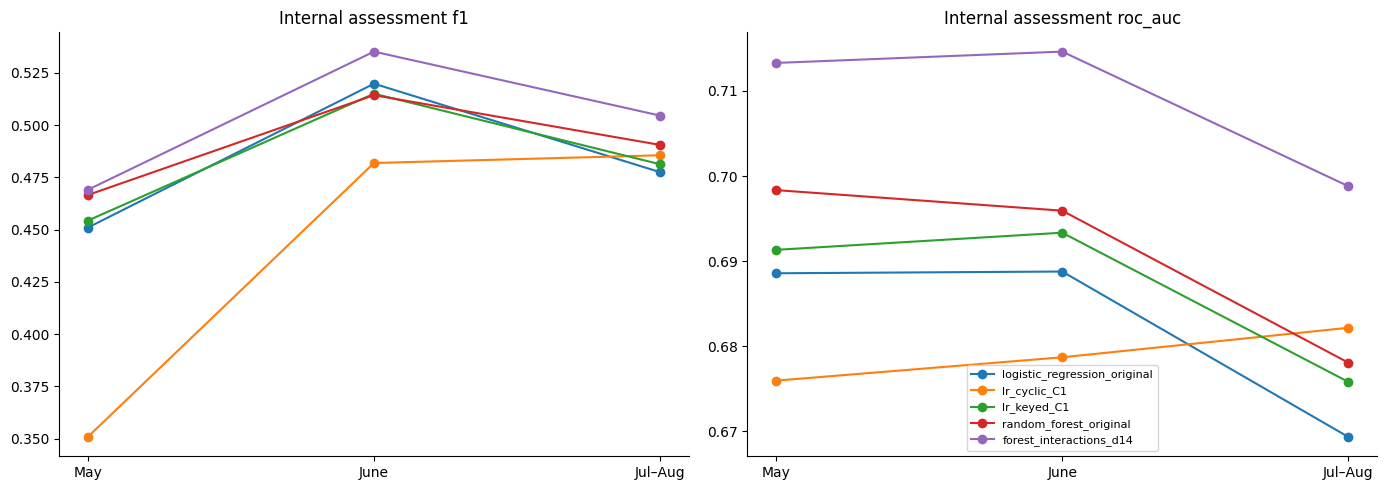

In [2]:
display(pd.read_csv(OUT/'development_monthly_coverage.csv'))
protocol=json.loads((OUT/'protocol.json').read_text())
display(pd.DataFrame(protocol['candidates'])[['name','family','encoding','parameters']])
display(pd.read_csv(OUT/'stability_comparison.csv'))
show=['logistic_regression_original','lr_cyclic_C1','lr_keyed_C1','random_forest_original','forest_interactions_d14']
fig,axes=plt.subplots(1,2,figsize=(14,5))
for name in show:
    g=internal.loc[internal.candidate.eq(name)]
    for ax,metric in zip(axes,['f1','roc_auc']):
        ax.plot(g.fold,g[metric],marker='o',label=name)
        ax.set(title=f'Internal assessment {metric}',xticks=[1,2,3],xticklabels=['May','June','Jul–Aug'])
axes[1].legend(fontsize=8); save('internal_stability')

## 2. Validation-only comparison

Final candidates fit January–August, and original models are loaded unchanged. September–October selects new thresholds using the same small F1 grid as the original workflow. These are development results, with optimistic threshold-selected F1. Monthly scores reuse the aggregate selected threshold and are not independent assessments.

Accuracy, balanced accuracy, precision, recall and F1 depend on the threshold. ROC-AUC and average precision depend on probability rankings. AP is the non-interpolated PR summary, not trapezoidal curve area. The always-positive reference detects every delay but has precision equal to prevalence; the majority reference has undefined precision and zero recall. NaN means undefined.

,candidate,threshold,accuracy,balanced_accuracy,precision,recall,f1
0,logistic_regression_original,0.325,0.639695,0.629892,0.233022,0.615911,0.338120
1,decision_tree_original,0.175,0.625442,0.615331,0.221858,0.600912,0.324069
2,random_forest_original,0.250,0.577373,0.633514,0.219188,0.713583,0.335363
3,lr_cyclic_C1,0.250,0.658019,0.633641,0.240855,0.598872,0.343544
4,lr_keyed_C1,0.300,0.614254,0.631208,0.226592,0.655388,0.336755
5,lr_interactions_C1,0.225,0.632111,0.636364,0.233871,0.642429,0.342908
6,forest_interactions_d14,0.275,0.654164,0.629396,0.237378,0.594072,0.339214
7,majority,0.500,0.850578,0.500000,NaN,0.000000,0.000000
8,always_positive,0.500,0.149422,0.500000,0.149422,1.000000,0.259995


,candidate,n,positive_count,prevalence,roc_auc,average_precision,brier,log_loss
0,logistic_regression_original,55775,8334,0.149422,0.675439,0.246266,0.148828,0.464342
1,decision_tree_original,55775,8334,0.149422,0.630173,0.199055,0.185200,0.557652
2,random_forest_original,55775,8334,0.149422,0.675547,0.247750,0.131853,0.435926
3,lr_cyclic_C1,55775,8334,0.149422,0.683829,0.255234,0.127963,0.413731
4,lr_keyed_C1,55775,8334,0.149422,0.675184,0.243595,0.147321,0.459979
5,lr_interactions_C1,55775,8334,0.149422,0.680481,0.250381,0.127945,0.413427
6,forest_interactions_d14,55775,8334,0.149422,0.679429,0.251076,0.128642,0.423589
7,majority,55775,8334,0.149422,0.500000,0.149422,0.149422,4.128676
8,always_positive,55775,8334,0.149422,0.500000,0.149422,0.850578,23.502363


,candidate,month,n,positive_count,negative_count,prevalence,f1,roc_auc,average_precision
0,logistic_regression_original,9,27122,3908,23214,0.144090,0.318553,0.663322,0.223430
1,logistic_regression_original,10,28653,4426,24227,0.154469,0.355075,0.685994,0.266057
2,decision_tree_original,9,27122,3908,23214,0.144090,0.310209,0.635657,0.199472
3,decision_tree_original,10,28653,4426,24227,0.154469,0.336692,0.624664,0.199147
4,random_forest_original,9,27122,3908,23214,0.144090,0.319761,0.661570,0.222182
5,random_forest_original,10,28653,4426,24227,0.154469,0.349799,0.688012,0.273422
6,lr_cyclic_C1,9,27122,3908,23214,0.144090,0.326436,0.672246,0.233593
7,lr_cyclic_C1,10,28653,4426,24227,0.154469,0.361041,0.696135,0.282037
8,lr_keyed_C1,9,27122,3908,23214,0.144090,0.319663,0.663369,0.223862
9,lr_keyed_C1,10,28653,4426,24227,0.154469,0.351809,0.685585,0.261573


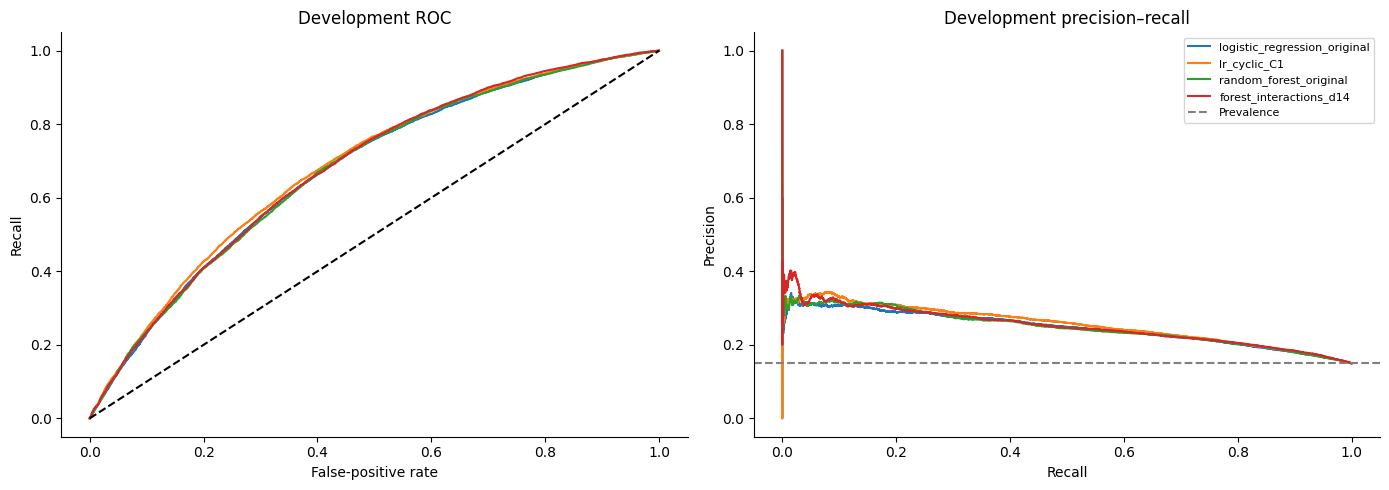

In [3]:
display(validation[['candidate','threshold','accuracy','balanced_accuracy','precision','recall','f1']])
display(validation[['candidate','n','positive_count','prevalence','roc_auc','average_precision','brier','log_loss']])
display(monthly[['candidate','month','n','positive_count','negative_count','prevalence','f1','roc_auc','average_precision']])
pred=pd.read_csv(OUT/'validation_predictions.csv')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for name in ['logistic_regression_original','lr_cyclic_C1','random_forest_original','forest_interactions_d14']:
    g=pred.loc[pred.candidate.eq(name)]
    fpr,tpr,_=roc_curve(g.target,g.probability)
    precision,recall,_=precision_recall_curve(g.target,g.probability)
    axes[0].plot(fpr,tpr,label=name); axes[1].plot(recall,precision,label=name)
axes[0].plot([0,1],[0,1],'k--'); axes[0].set(title='Development ROC',xlabel='False-positive rate',ylabel='Recall')
axes[1].axhline(validation.prevalence.iloc[0],color='gray',linestyle='--',label='Prevalence')
axes[1].set(title='Development precision–recall',xlabel='Recall',ylabel='Precision'); axes[1].legend(fontsize=8)
save('validation_ranking')

## 3. Threshold transfer and stability

Cyclic logistic has validation F1 0.3435 vs original 0.3381 and ROC-AUC 0.6838 vs 0.6754, improving F1 in both validation months. But its internal mean F1 is lower, and transferred internal thresholds remove the F1 gain. The engineered depth-14 forest improves all three internal periods, then gives a smaller validation gain over the original forest (F1 0.3392 vs 0.3354).

The following comparison freezes the threshold at each candidate's median internal choice before considering validation labels. Its scores are a threshold-transfer diagnostic, not a replacement selection process.

,candidate,internal_median_threshold,precision,recall,f1,roc_auc
0,decision_tree_original,0.100,0.173407,0.895728,0.290563,0.630173
1,forest_interactions_d14,0.225,0.212590,0.758579,0.332108,0.679429
2,logistic_regression_original,0.225,0.202094,0.796736,0.322408,0.675439
3,lr_cyclic_C1,0.150,0.200912,0.814255,0.322299,0.683829
4,lr_interactions_C1,0.150,0.202184,0.806335,0.323302,0.680481
5,lr_keyed_C1,0.225,0.204132,0.790737,0.324495,0.675184
6,random_forest_original,0.200,0.170443,0.935085,0.288331,0.675547


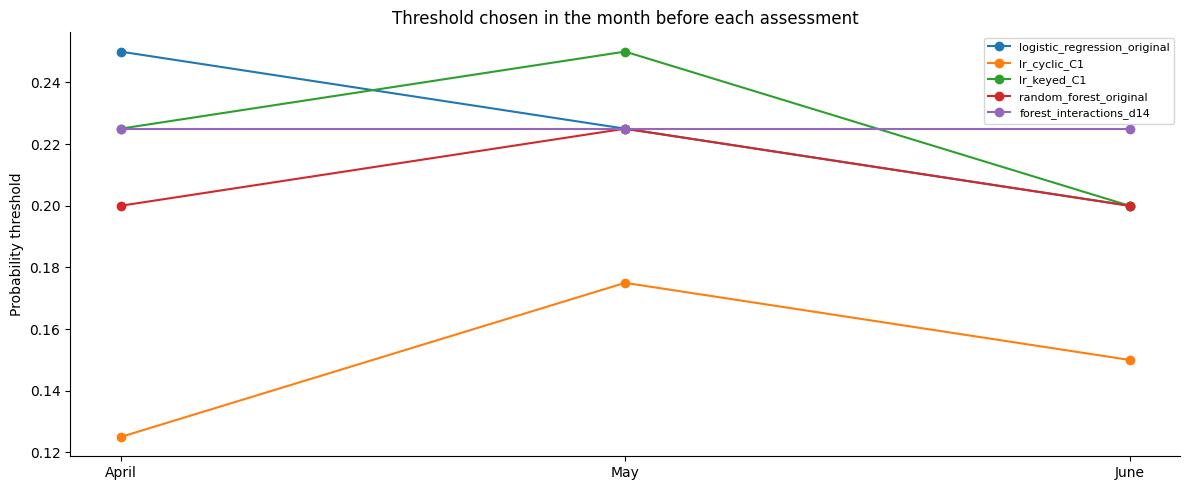

In [4]:
display(pd.read_csv(OUT/'threshold_transfer.csv')[['candidate','internal_median_threshold','precision','recall','f1','roc_auc']])
fig,ax=plt.subplots()
for name in show:
    g=internal.loc[internal.candidate.eq(name)]
    ax.plot(g.fold,g.threshold,marker='o',label=name)
ax.set(title='Threshold chosen in the month before each assessment',xticks=[1,2,3],xticklabels=['April','May','June'],ylabel='Probability threshold')
ax.legend(fontsize=8); save('threshold_transfer')

## 4. Calibration before numerical risk estimates

The internal forest winner has a matched calibration experiment: base fits Jan–Jun, sigmoid fits July only, threshold fits August only, and assessment uses Sep–Oct. Both raw and calibrated variants have the identical base model. Do not compare them directly with the Jan–Aug finalists as a pure calibration effect.

The sigmoid **worsens** Brier score (0.1276 → 0.1421) and log loss (0.4207 → 0.4486), including both months. July prevalence is much higher than the later assessment. An increasing sigmoid preserves ranking, so unchanged ROC-AUC does not validate numerical risk quality. Brier/log loss combine calibration and discrimination; reliability diagrams and bin counts are also needed. Do not adopt this calibration or claim calibrated dashboard percentages.

,method,assessment,threshold,n,negative_count,positive_count,prevalence,predicted_positive_count,precision,recall,...,roc_auc,tn,fp,fn,tp,accuracy,balanced_accuracy,average_precision,brier,log_loss
0,raw,Sep-Oct,0.225,55775,47441,8334,0.149422,29599,0.213183,0.757139,...,0.680109,24152,23289,2024,6310,0.546159,0.633117,0.250472,0.127570,0.420680
1,raw,9,0.225,27122,23214,3908,0.144090,14373,0.202602,0.745138,...,0.664092,11753,11461,996,2912,0.540705,0.625714,0.221974,0.126281,0.418171
2,raw,10,0.225,28653,24227,4426,0.154469,15226,0.223171,0.767736,...,0.694483,12399,11828,1028,3398,0.551321,0.639760,0.280389,0.128790,0.423056
3,sigmoid,Sep-Oct,0.250,55775,47441,8334,0.149422,29799,0.212490,0.759779,...,0.680109,23974,23467,2002,6332,0.543362,0.632561,0.250472,0.142086,0.448555
4,sigmoid,9,0.250,27122,23214,3908,0.144090,14468,0.201894,0.747441,...,0.664092,11667,11547,987,2921,0.537866,0.625013,0.221974,0.142804,0.450285
5,sigmoid,10,0.250,28653,24227,4426,0.154469,15331,0.222490,0.770673,...,0.694483,12307,11920,1015,3411,0.548564,0.639330,0.280389,0.141407,0.446917


,reference,training_prevalence,brier,log_loss
0,training_prior_Jan_to_6,0.232733,0.134036,0.443172
1,training_prior_Jan_to_8,0.241376,0.135550,0.447359


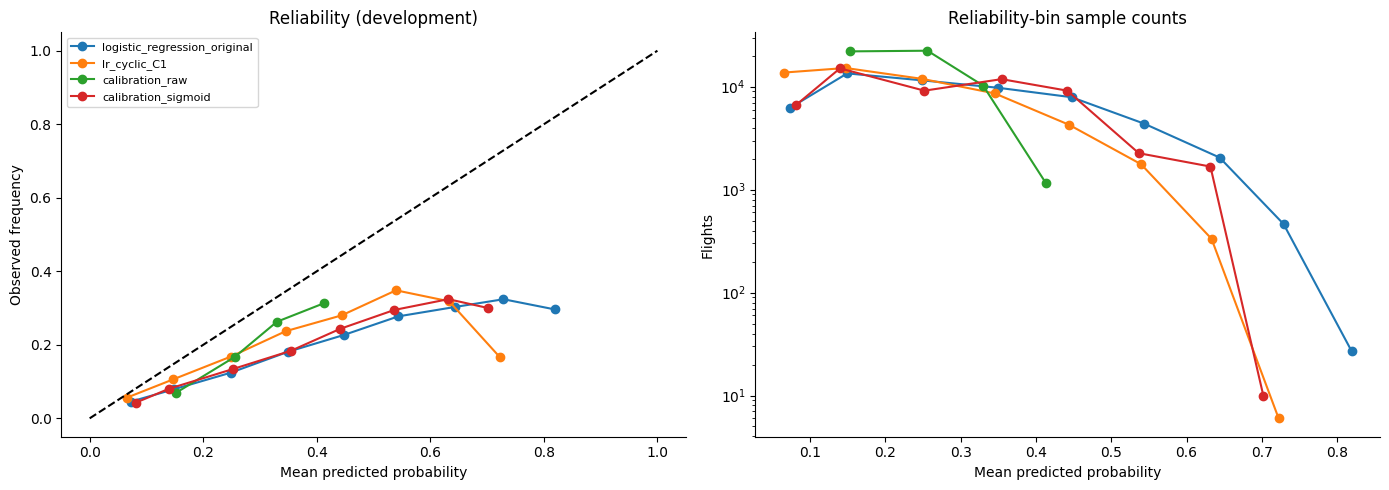

,bin,n,predicted,observed,model
51,"(0.1, 0.2]",22027,0.152556,0.069914,calibration_raw
52,"(0.2, 0.3]",22355,0.255852,0.167390,calibration_raw
53,"(0.3, 0.4]",10245,0.329786,0.262762,calibration_raw
54,"(0.4, 0.5]",1148,0.413451,0.313589,calibration_raw
55,"(-0.001, 0.1]",6636,0.081266,0.042646,calibration_sigmoid
56,"(0.1, 0.2]",15065,0.139634,0.080451,calibration_sigmoid
57,"(0.2, 0.3]",9147,0.251723,0.133814,calibration_sigmoid
58,"(0.3, 0.4]",11834,0.354332,0.183708,calibration_sigmoid
59,"(0.4, 0.5]",9149,0.441505,0.243633,calibration_sigmoid
60,"(0.5, 0.6]",2259,0.536563,0.294821,calibration_sigmoid


In [5]:
display(pd.read_csv(OUT/'calibration_metrics.csv'))
display(pd.read_csv(OUT/'probability_references.csv')[['reference','training_prevalence','brier','log_loss']])
bins=pd.read_csv(OUT/'reliability_bins.csv')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for name in ['logistic_regression_original','lr_cyclic_C1','calibration_raw','calibration_sigmoid']:
    g=bins.loc[bins.model.eq(name)]
    axes[0].plot(g.predicted,g.observed,marker='o',label=name)
    axes[1].plot(g.predicted,g.n,marker='o',label=name)
axes[0].plot([0,1],[0,1],'k--'); axes[0].set(title='Reliability (development)',xlabel='Mean predicted probability',ylabel='Observed frequency')
axes[1].set(title='Reliability-bin sample counts',xlabel='Mean predicted probability',ylabel='Flights',yscale='log')
axes[0].legend(fontsize=8); save('probability_reliability')
display(bins.loc[bins.model.isin(['calibration_raw','calibration_sigmoid'])])

## 5. Feature-group importance without test data

For the internal winner fitted Jan–Aug, jointly permute each raw feature group on Sep–Oct and recompute engineered features. Three repeats report drops in ranking and fixed-threshold metrics. This shuffle is only an attribution diagnostic, never model fitting. Correlation and unrealistic recombinations limit interpretation; these are not causal effects or a feature-removal rule.

auc_drop             ap_drop             f1_drop          
                    mean       std      mean       std      mean       std
group                                                                     
airline_flight  0.019956  0.000284  0.020669  0.001668  0.015511  0.000947
airports        0.005049  0.000087  0.005423  0.001731  0.003248  0.000882
clocks          0.147829  0.002474  0.079492  0.000802  0.110474  0.000926
distance        0.000553  0.000101  0.000403  0.000301  0.000285  0.000480
season          0.000086  0.000015  0.000105  0.000106  0.000345  0.000216
weekday         0.006235  0.000518  0.011005  0.000647  0.006656  0.000377

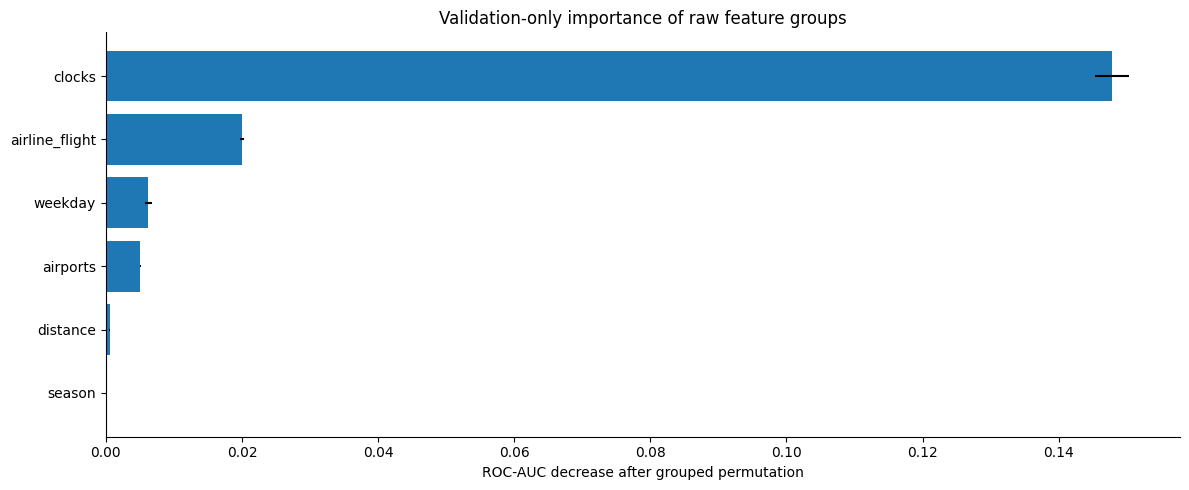

In [6]:
importance=pd.read_csv(OUT/'group_importance.csv')
summary_importance=importance.groupby('group')[['auc_drop','ap_drop','f1_drop']].agg(['mean','std'])
display(summary_importance)
g=importance.groupby('group').auc_drop.agg(['mean','std']).sort_values('mean')
plt.barh(g.index,g['mean'],xerr=g['std']); plt.xlabel('ROC-AUC decrease after grouped permutation')
plt.title('Validation-only importance of raw feature groups'); save('feature_group_importance')

## 6. Recommendations and implementation checks

Retain the original selected model pending review. Keep temporal internal validation, the positive dummy reference, probability metrics and threshold-transfer checks. Keep the enhanced shallow forest as a research candidate, and cyclic logistic as an exploratory alternative with mixed stability. Do not add interaction complexity, deeper forests, carrier-qualified IDs alone as a performance claim, or the tested July sigmoid.

Tests now also cover experimental chronology, sentinel test-target exclusion, deterministic features, midnight wrapping, estimator cloning and fresh-process artifact loading. The preservation manifest verifies original artifacts remain unchanged. NumPy and joblib should eventually be explicit direct dependencies; notebook tooling can be listed separately. Requirements remain unchanged for this study.

September–October has already been used in the original project and this study. The old test was historically examined by the team; no fresh test claim can be made here. This is bounded exploratory evidence, not proof of generalization. No integration or dashboard is included.

In [7]:
assert protected_hashes()==json.loads((OUT/'preservation_check.json').read_text())['files']
print('Historical baseline still unchanged. No test inference was performed.')
print('Full report:',ROOT/'reports/modeling_improvement_study.md')

Historical baseline still unchanged. No test inference was performed.
Full report: /Users/animusoyan/PycharmProjects/Data_Mining_Project/reports/modeling_improvement_study.md
